# 02 — Experiment Results

The code lives in `src/experiments/`; this notebook only calls it and shows the
output.

### Prerequisites
| Part | Needs |
|---|---|
| 1 | the ε sweep's saved tables: `python -m src.experiments.threshold` (hours on NUMOSIM, so this notebook reads its results instead of re-running it) |
| 2 | module 1's NHTS and Geolife templates; IBAD's saved Geolife models, on Geolife's and on NHTS's templates |

Equivalent one-shot command: `bash scripts/experiments/run_experiments.sh`.
How to run each experiment: `src/experiments/README.md`.

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

REPO_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(REPO_ROOT))

import torch

from src.detection.run import CONFIG_PATH
from src.experiments import plots, threshold, transfer
from src.utils.config import load_cfg

cfg = load_cfg(CONFIG_PATH)      # the benchmark every method shares
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"seeds={cfg['replicate_seeds']}  device={device}")

seeds=[42, 43, 44, 45, 46]  device=cuda


---
## Part 1 — Effect of the dissimilarity threshold ε

### 1a — Load the sweep

In [2]:
exp_eps = load_cfg(threshold.EXPERIMENT_CONFIG)
tables = threshold.load_results(exp_eps)
{d: f"{t.method.nunique()} methods, {t.seed.nunique()} seeds, ε = {sorted(t.eps.unique().tolist())}"
 for d, t in tables.items()}

{'geolife': '10 methods, 5 seeds, ε = [0.0, 0.05, 0.1, 0.25]',
 'numosim': '10 methods, 5 seeds, ε = [0.0, 0.05, 0.1, 0.25]'}

### 1b — What ε does to the benchmark

`agents_spliced` is how many agents received a splice, and `mean_shift_nats` means on average, how different the injected anomalies actually are.

In [3]:
threshold.splice_stats(tables)

agents_spliced  mean_shift_nats
dataset policy   eps                                  
geolife combined 0.00              70            0.328
                 0.05              70            0.342
                 0.10              70            0.372
                 0.25              70            0.485
        inter    0.00              70            0.333
                 0.05              70            0.358
                 0.10              70            0.389
                 0.25              70            0.495
        intra    0.00              70            0.295
                 0.05              70            0.321
                 0.10              70            0.352
                 0.25              70            0.462
numosim combined 0.00          200000            0.313
                 0.05          200000            0.358
                 0.10          200000            0.395
                 0.25          200000            0.500
        inter    0.00          200000            0.381
                 0.05          200000            0.425
                 0.10          200000            0.459
                 0.25          200000            0.540
        intra    0.00          200000            0.245
                 0.05          199691            0.291
                 0.10          198608            0.330
                 0.25          184176            0.452

### 1c — Results

Mean ± 1 sd over five seeds, `combined` policy, NUMOSIM on top and Geolife below. The rows, methods and layout come from the `figure` section of
`configs/experiments/threshold.yaml`.

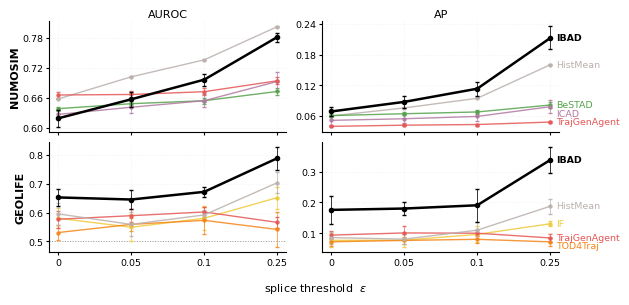

In [4]:
fig = threshold.figure(tables, exp_eps)


AUROC and AP on `combined` policy, Geolife then NUMOSIM. The `inter` and `intra`
policies are in the same tables (`policy=` argument).

In [5]:
print("---------------------- Gelife ----------------------")
display(threshold.table(tables["geolife"], "ap"))
print("---------------------- Numosim ----------------------")
display(threshold.table(tables["numosim"], "ap"))

---------------------- Gelife ----------------------


,ε = 0,ε = 0.05,ε = 0.1,ε = 0.25
IBAD,0.176 ± 0.045,0.180 ± 0.021,0.191 ± 0.053,0.338 ± 0.043
HistMean,0.086 ± 0.019,0.081 ± 0.016,0.110 ± 0.028,0.188 ± 0.024
GHMM,0.072 ± 0.012,0.062 ± 0.016,0.076 ± 0.009,0.079 ± 0.012
IF,0.077 ± 0.022,0.078 ± 0.021,0.097 ± 0.026,0.131 ± 0.009
OCSVM,0.071 ± 0.016,0.068 ± 0.004,0.069 ± 0.007,0.104 ± 0.025
DeepSVDD,0.061 ± 0.010,0.064 ± 0.015,0.068 ± 0.012,0.089 ± 0.013
BeSTAD,0.072 ± 0.020,0.083 ± 0.029,0.100 ± 0.013,0.099 ± 0.035
TOD4Traj,0.072 ± 0.013,0.077 ± 0.012,0.081 ± 0.013,0.072 ± 0.013
ICAD,0.055 ± 0.011,0.060 ± 0.007,0.058 ± 0.009,0.056 ± 0.010
TrajGenAgent,0.094 ± 0.013,0.101 ± 0.023,0.100 ± 0.010,0.085 ± 0.013


---------------------- Numosim ----------------------


,ε = 0,ε = 0.05,ε = 0.1,ε = 0.25
IBAD,0.069 ± 0.009,0.088 ± 0.012,0.114 ± 0.014,0.213 ± 0.022
HistMean,0.061 ± 0.000,0.076 ± 0.000,0.095 ± 0.000,0.160 ± 0.001
GHMM,0.029 ± 0.002,0.034 ± 0.003,0.036 ± 0.003,0.043 ± 0.005
IF,0.034 ± 0.001,0.046 ± 0.001,0.062 ± 0.002,0.112 ± 0.006
OCSVM,0.022 ± 0.000,0.021 ± 0.000,0.022 ± 0.000,0.029 ± 0.000
DeepSVDD,0.025 ± 0.003,0.025 ± 0.003,0.024 ± 0.003,0.024 ± 0.004
BeSTAD,0.061 ± 0.003,0.065 ± 0.003,0.068 ± 0.004,0.082 ± 0.006
TOD4Traj,0.019 ± 0.000,0.019 ± 0.000,0.019 ± 0.000,0.019 ± 0.000
ICAD,0.052 ± 0.008,0.055 ± 0.009,0.060 ± 0.009,0.079 ± 0.013
TrajGenAgent,0.040 ± 0.001,0.043 ± 0.002,0.044 ± 0.002,0.049 ± 0.002


---
## Part 2 — Transferability of templates (NHTS → Geolife)

### 2a — Alignment

Each template is a distribution over (15-minute slot, activity) cells. On the 17
shared activities, NHTS and Geolife templates are paired by Hungarian matching to
maximise total cosine similarity; the statistic is the mean matched similarity.
The null shuffles each Geolife template's cells independently and rematches,
1,000 times.

In [11]:
exp_transfer = load_cfg(transfer.EXPERIMENT_CONFIG)
alignment = transfer.alignment(exp_transfer, cfg)
{k: round(alignment[k], 4) for k in ("mean_matched_cosine", "null_mean", "null_sd", "z", "p_value")}

{'mean_matched_cosine': 0.6741,
 'null_mean': 0.0971,
 'null_sd': 0.0086,
 'z': 66.7116,
 'p_value': 0.001}

In [14]:
(alignment["pairs"]
 .rename(columns={"source_top_activities": "NHTS", "target_top_activities": "Geolife"})
 .sort_values("cosine", ascending=False)
 .round(3))

,source_template,target_template,cosine,NHTS,Geolife
3,3,0,0.990,"Home 93%, Shopping 3%, Religious 1%","Home 98%, Restaurant 1%, Shopping 0%"
4,4,4,0.905,"Home 58%, Work 40%, Restaurant 1%","Home 50%, Work 47%, Restaurant 2%"
1,1,1,0.790,"Home 48%, Excercise 13%, Recreation 11%","Home 45%, Transportation 13%, Shopping 10%"
5,5,5,0.660,"Home 64%, Education 33%, Health 3%","Education 69%, Home 19%, Work 8%"
0,0,2,0.352,"Home 54%, Work 41%, Religious 3%","Restaurant 24%, Home 23%, Social 19%"
2,2,3,0.347,"Home 60%, Social 20%, Recreation 11%","Recreation 38%, Social 37%, Home 19%"


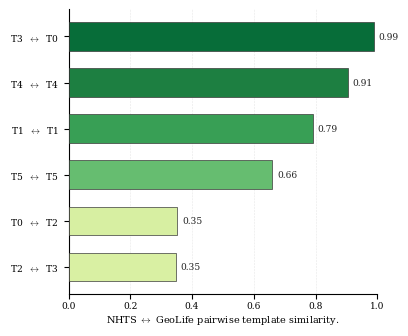

In [15]:
fig = plots.alignment_pairs_figure(alignment)

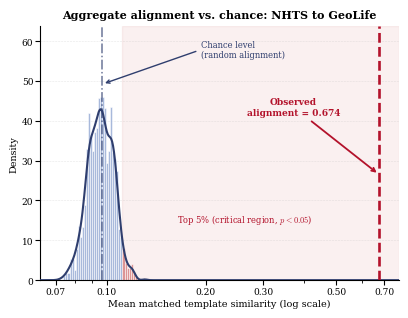

In [16]:
fig = plots.alignment_null_figure(alignment)

The matched templates are far more alike than chance. Stay-at-home, work and
study days line up closely across the two populations; the two weak pairs are
where the datasets carve days differently — NHTS has two work templates where
Geolife has one, and Geolife spends its remaining templates on eating out and
socialising.

### 2b — Transferability on Anomaly Detection Results


In [18]:
utility = transfer.utility(exp_transfer, cfg, cfg['replicate_seeds'], device)

  sequences: 70 agents x 947 days x 17 visits (p100); 18,739 visits placed
  sequences: 70 agents x 947 days x 17 visits (p100); 18,739 visits placed

=== transfer · nhts -> geolife · seed 42 ===
  IBAD: 251,062 parameters
  loading artifacts/detection/geolife_ibad_seed42.pt
  inter: 70/70 agents spliced in test
  intra: 70/70 agents spliced in test
  combined: 70/70 agents spliced in test
  inter     native       AUROC=0.7048 AP=0.2121
  intra     native       AUROC=0.6218 AP=0.1774
  combined  native       AUROC=0.5917 AP=0.1754
  IBAD: 251,062 parameters
  loading artifacts/experiments/transfer/geolife_ibad_nhts_seed42.pt
  inter: 70/70 agents spliced in test
  intra: 70/70 agents spliced in test
  combined: 70/70 agents spliced in test
  inter     transferred  AUROC=0.6450 AP=0.1759
  intra     transferred  AUROC=0.5989 AP=0.1199
  combined  transferred  AUROC=0.6058 AP=0.1251

=== transfer · nhts -> geolife · seed 43 ===
  IBAD: 251,062 parameters
  loading artifacts/detection/geo

Mean ± sd over five seeds. `*_native` means we used Geolife's templates for training and evalution, while `*_transferred` means we assigned NHTS templated to Geolife daily visit sequences.

In [20]:
transfer.utility_summary(utility)

,policy,auroc_native,auroc_transferred,ap_native,ap_transferred
0,combined,0.646 ± 0.034,0.632 ± 0.022,0.180 ± 0.021,0.150 ± 0.029
1,inter,0.688 ± 0.036,0.661 ± 0.020,0.196 ± 0.036,0.202 ± 0.026
2,intra,0.606 ± 0.013,0.598 ± 0.008,0.154 ± 0.027,0.132 ± 0.038
